# A tour of figfont

One figure, from first draft to the page. Every function in the package is used once, in the
order you would reach for it:

1. Draw a figure the usual way
2. Work out the size it prints at
3. Measure what prints
4. Compare with published papers
5. Set the printed sizes
6. Find colliding text
7. Fix colliding text
8. Measure it again
9. Pick a size for small panels
10. Boxed notes on a map
11. The command line

The output of every cell is saved in the notebook, so it reads top to bottom without running
anything. To run it yourself, install figfont with OCR, Jupyter, and cartopy for section 10:

```bash
pip install "figfont[mac] @ git+https://github.com/jake-casselman/figfont" jupyter cartopy
jupyter lab docs/tour.ipynb
```

On Linux or Windows use `figfont[tesseract]` and install the tesseract command.

In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # show each figure whole, edges and all
%config InlineBackend.figure_format = "retina"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import figfont
from figfont.mpl import scale_fonts, set_printed_fonts

out = Path("tour_output")    # the files this notebook saves
out.mkdir(exist_ok=True)

figfont.__version__

'0.2.3'

## 1. Draw a figure the usual way

Three panels, drawn 13 in wide because that is comfortable on a screen. Nothing here knows about
figfont yet. The text is matplotlib's own 10 pt.

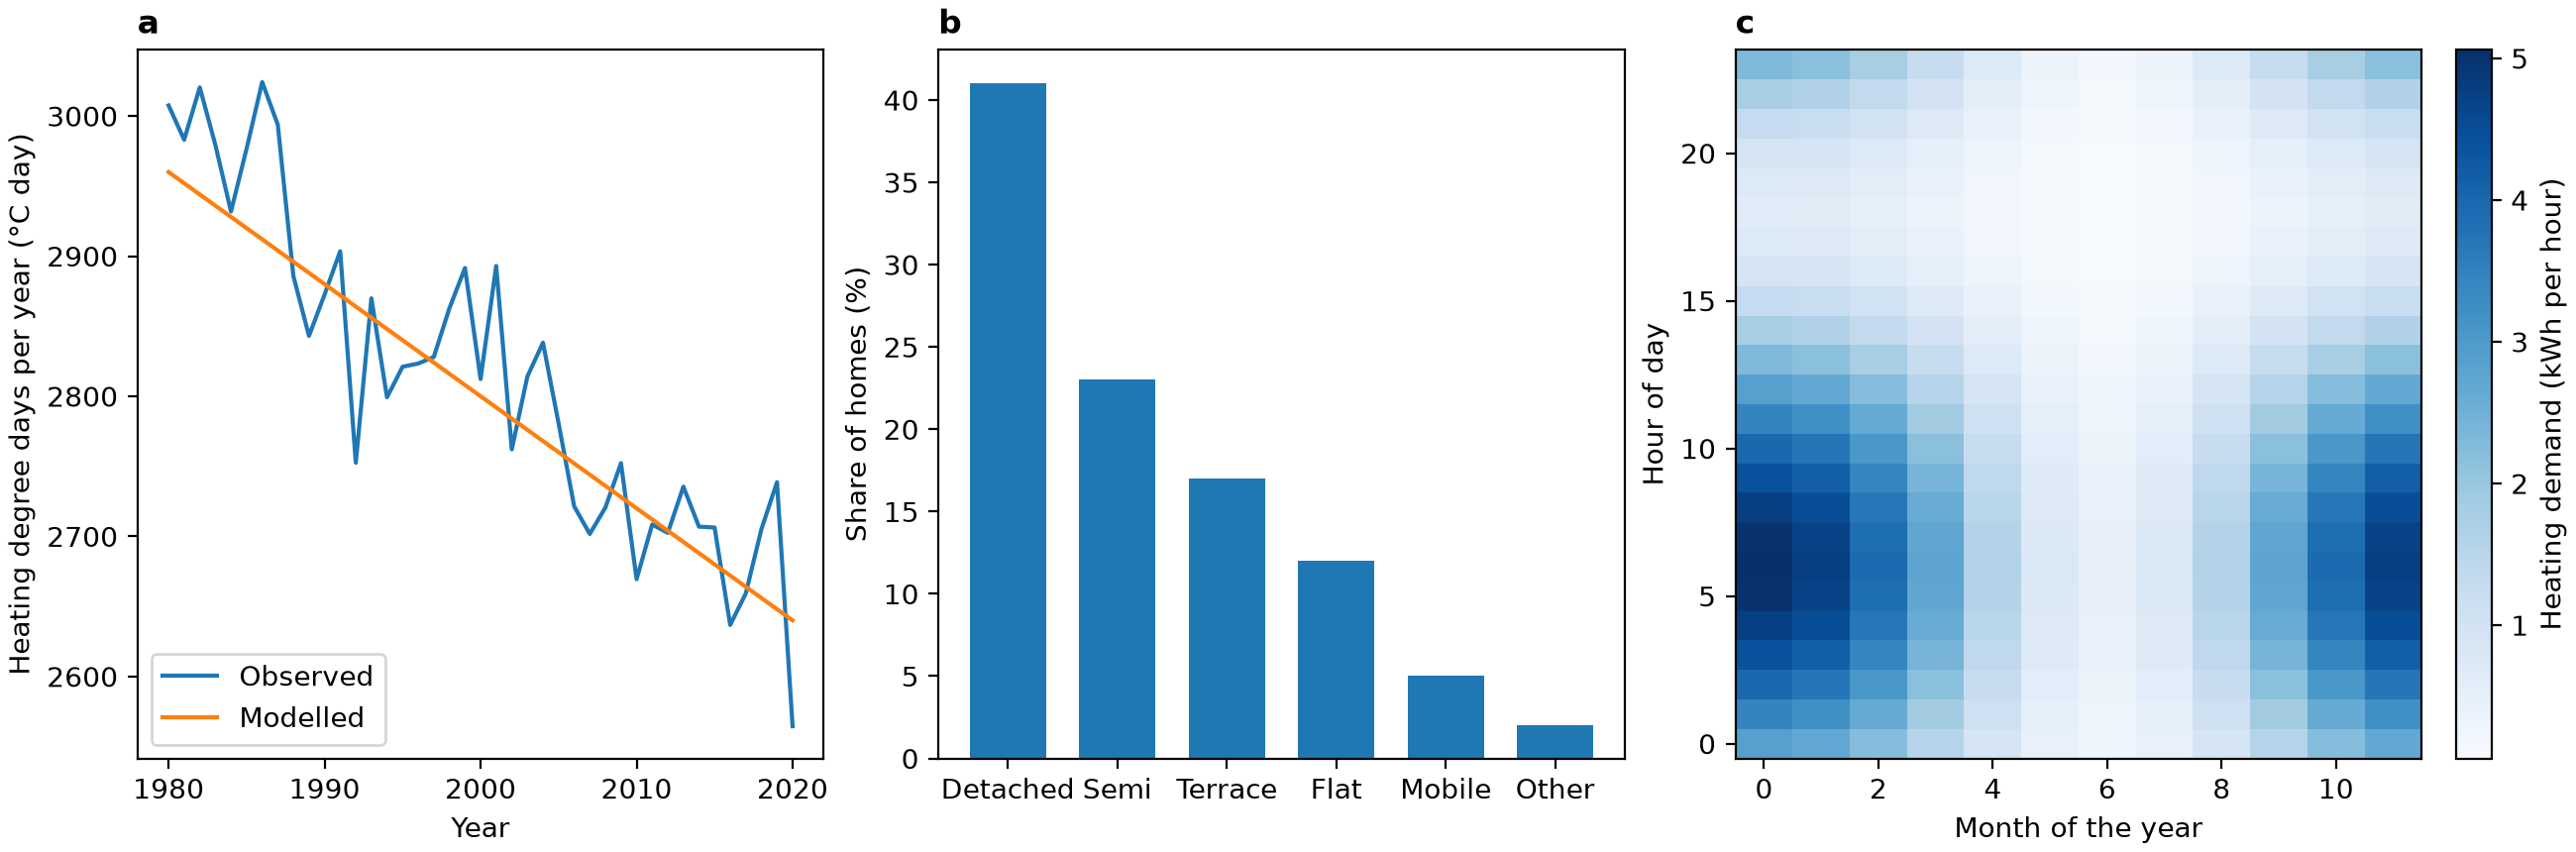

In [2]:
def draft():
    rng = np.random.default_rng(0)
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(13, 4.3), layout="constrained")
    years = np.arange(1980, 2021)
    a.plot(years, 3000 - 9 * (years - 1980) + rng.normal(0, 60, years.size), label="Observed")
    a.plot(years, 2960 - 8 * (years - 1980), label="Modelled")
    a.set_xlabel("Year")
    a.set_ylabel("Heating degree days per year (°C day)")
    a.legend(loc="lower left")
    b.bar(["Detached", "Semi", "Terrace", "Flat", "Mobile", "Other"], [41, 23, 17, 12, 5, 2], width=0.7)
    b.set_ylabel("Share of homes (%)")
    month, hour = np.meshgrid(np.arange(12), np.arange(24))
    demand = (1.2 + np.cos(2 * np.pi * month / 12)) * (1.3 + np.cos(2 * np.pi * (hour - 6) / 24))
    image = c.imshow(demand, aspect="auto", cmap="Blues", origin="lower")
    fig.colorbar(image, ax=c).set_label("Heating demand (kWh per hour)")
    c.set_xlabel("Month of the year")
    c.set_ylabel("Hour of day")
    for letter, ax in zip("abc", (a, b, c)):
        ax.set_title(letter, loc="left", fontweight="bold")
    return fig

fig = draft()

## 2. Work out the size it prints at

The journal places this figure across a 5.15 in text column. A 13 in figure on a 5.15 in page is
shrunk to 40 % of its size, and its text shrinks with it.

In [3]:
DRAWN = 13      # the width the figure is drawn at, inches
PAGE = 5.15     # the width it gets on the page, inches

round(figfont.printed_pt(10, DRAWN, PAGE), 2)     # what 10 pt text prints at

3.96

That is too small to read. Two ways to get 8 pt on the page:

In [4]:
round(figfont.drawn_pt_for(8, DRAWN, PAGE), 2)    # draw the text at this size

20.19

In [5]:
# or multiply every font by this
round(figfont.font_scale_for(8, figfont.printed_pt(10, DRAWN, PAGE)), 2)

2.02

A figure put together from separate panel images is as wide as all its panels side by side. These
two give the width of one panel on the page, and back:

In [6]:
panel = figfont.panel_width_for(PAGE, columns=3, gap=0.15, margin=0.1)
panel, figfont.stitched_width(panel, columns=3, gap=0.15, margin=0.1)

(1.55, 5.15)

## 3. Measure what prints

The arithmetic says 3.96 pt. `figure` checks it on the saved file: it reads every piece of text
in the figure and gives the size each one has when the figure is placed 5.15 in wide.

In [7]:
fig.savefig(out / "draft.pdf")

draft_result = figfont.figure(out / "draft.pdf", printed_width=PAGE)
draft_result.summary()

{'name': 'draft.pdf',
 'method': 'text',
 'n': 52,
 'median_pt': 3.96,
 'p10_pt': 3.96,
 'p90_pt': 3.96}

`method` is `text`: a PDF from matplotlib stores its font sizes, so the answer is exact.
`figure_pdf_text` is the function behind it. The result holds every size, not only the summary:

In [8]:
exact = figfont.figure_pdf_text(out / "draft.pdf", printed_width=PAGE)
exact.n, exact.median, exact.percentile(10), exact.sizes[:5]

(52, 3.96, 3.96, [3.96, 3.96, 3.96, 3.96, 3.96])

### Figures inside a compiled paper

`pdf_figure_text` takes the finished paper instead. It finds the text that sits inside the
figures, leaves out the body text and the captions, and needs no width because the figures are
already at their printed size. The paper here is a one-page example that comes with the package.

In [9]:
figfont.pdf_figure_text("examples/paper.pdf").summary()

{'name': 'paper.pdf',
 'method': 'text',
 'n': 45,
 'median_pt': 7.0,
 'p10_pt': 7.0,
 'p90_pt': 8.0}

## 4. Compare with published papers

Is 3.96 pt small? figfont carries the printed figure-text sizes of 111 journal articles.

In [10]:
figfont.reference()

{'papers': 111,
 'median_pt': 7.97,
 'p10_pt': 6.0,
 'p90_pt': 9.96,
 'paper_medians_p25_p75': [7.39, 8.97]}

In [11]:
figfont.reference("Nature")

{'papers': 7,
 'median_pt': 7.0,
 'p10_pt': 5.5,
 'p90_pt': 8.0,
 'paper_medians_p25_p75': [6.0, 7.0]}

`verdict` puts a figure next to those numbers and gives one word for it:

In [12]:
figfont.verdict(draft_result)

{'name': 'draft.pdf',
 'method': 'text',
 'n': 52,
 'median_pt': 3.96,
 'p10_pt': 3.96,
 'p90_pt': 3.96,
 'reference_median_pt': 7.97,
 'reference_range_pt': [7.39, 8.97],
 'verdict': 'small',
 'scale_to_reference': 2.01}

`small`, and `scale_to_reference` says the text needs to be twice as big. The same thing as a
picture, which section 8 uses again:

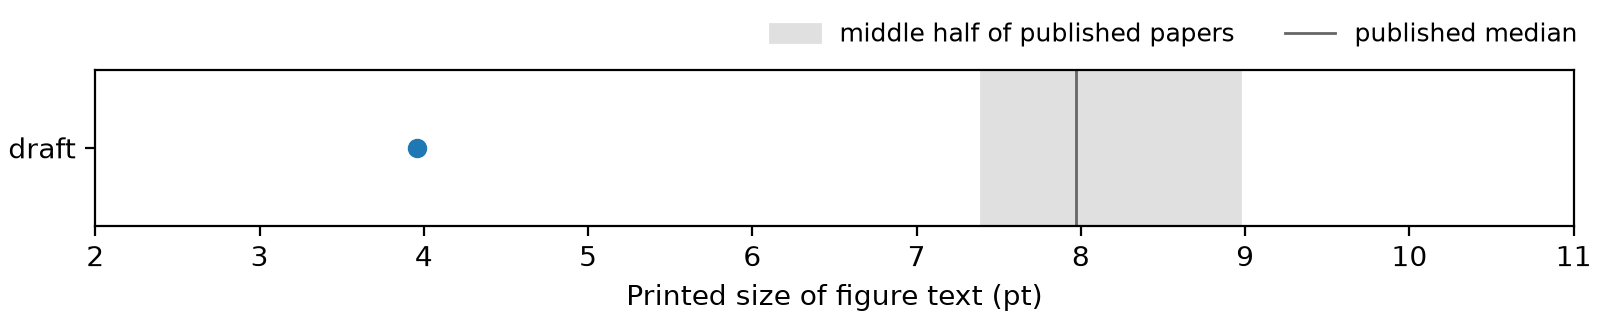

In [13]:
def against_papers(results):
    """Each figure's text sizes on one line, over the sizes in published papers."""
    papers = figfont.reference()
    plot, ax = plt.subplots(figsize=(8, 1.2 + 0.4 * len(results)), layout="constrained")
    ax.axvspan(*papers["paper_medians_p25_p75"], color="0.88", label="middle half of published papers")
    ax.axvline(papers["median_pt"], color="0.4", linewidth=1, label="published median")
    for row, (name, result) in enumerate(results.items()):
        ax.plot([result.percentile(10), result.percentile(90)], [row, row], color="C0", linewidth=3)
        ax.plot(result.median, row, "o", color="C0")
    ax.set_yticks(range(len(results)), list(results))
    ax.set_ylim(len(results) - 0.4, -0.6)
    ax.set_xlim(2, 11)
    ax.set_xlabel("Printed size of figure text (pt)")
    plot.legend(loc="outside upper right", ncols=2, fontsize=9, frameon=False)

against_papers({"draft": draft_result})

## 5. Set the printed sizes

`set_printed_fonts` sets every piece of text so that it prints at a chosen size on a page of the
given width. The defaults are 7 pt for tick labels and 8 pt for everything else.

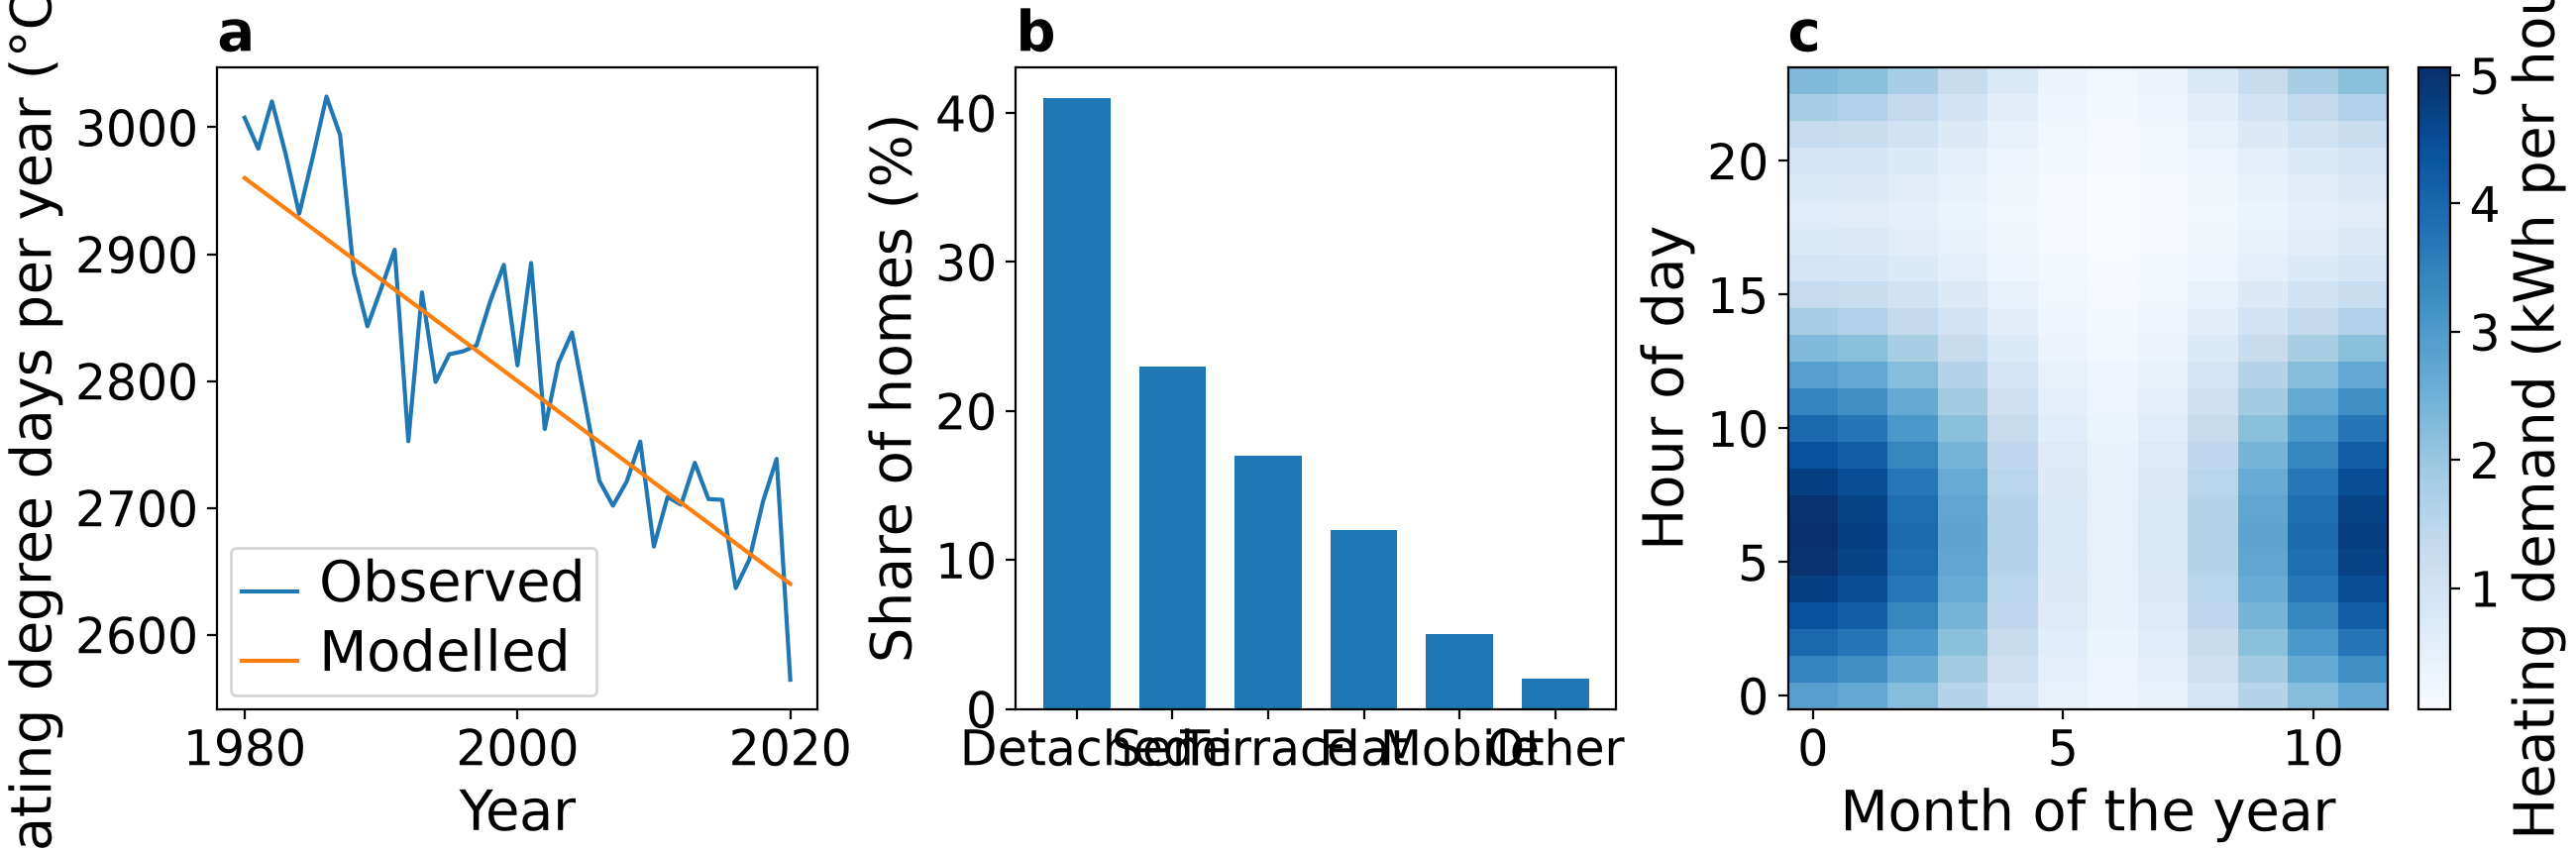

In [14]:
set_printed_fonts(fig, printed_width=PAGE)
fig

The text is now the right size, and the layout is broken: the bar names run into each other, the
axis labels touch their numbers, and the long label on the right is cut off. That is the second
half of the job.

To change one of the sizes, pass it: `set_printed_fonts(fig, PAGE, sizes={"tick": 8})`. The keys
are `tick`, `label`, `title`, `legend` and `other`.

## 6. Find colliding text

`report_overlaps` prints every piece of text that touches other text or lies on a neighbouring
panel, and with `edges=True` text that runs off the figure. It returns how many it found.

In [15]:
figfont.report_overlaps(fig, "fig01", edges=True)

TEXT OFF THE FIGURE fig01: 'Heating degree days per year (°C day)'


TEXT OVERLAP fig01: 'Detached' <-> 'Semi'


TEXT OVERLAP fig01: 'Detached' <-> 'Terrace'


TEXT OVERLAP fig01: 'Detached' <-> '0'


TEXT OVERLAP fig01: 'Semi' <-> 'Terrace'


TEXT OVERLAP fig01: 'Terrace' <-> 'Flat'


TEXT OVERLAP fig01: 'Flat' <-> 'Mobile'


TEXT OVERLAP fig01: 'Mobile' <-> 'Other'


TEXT OFF THE FIGURE fig01: 'Heating demand (kWh per hour)'


9

`overlaps` returns the same list as objects: the text, what it touches, and the kind of
collision. They are matplotlib's own `Text` objects, so you can do what you like with them. Here,
a red box round each one:

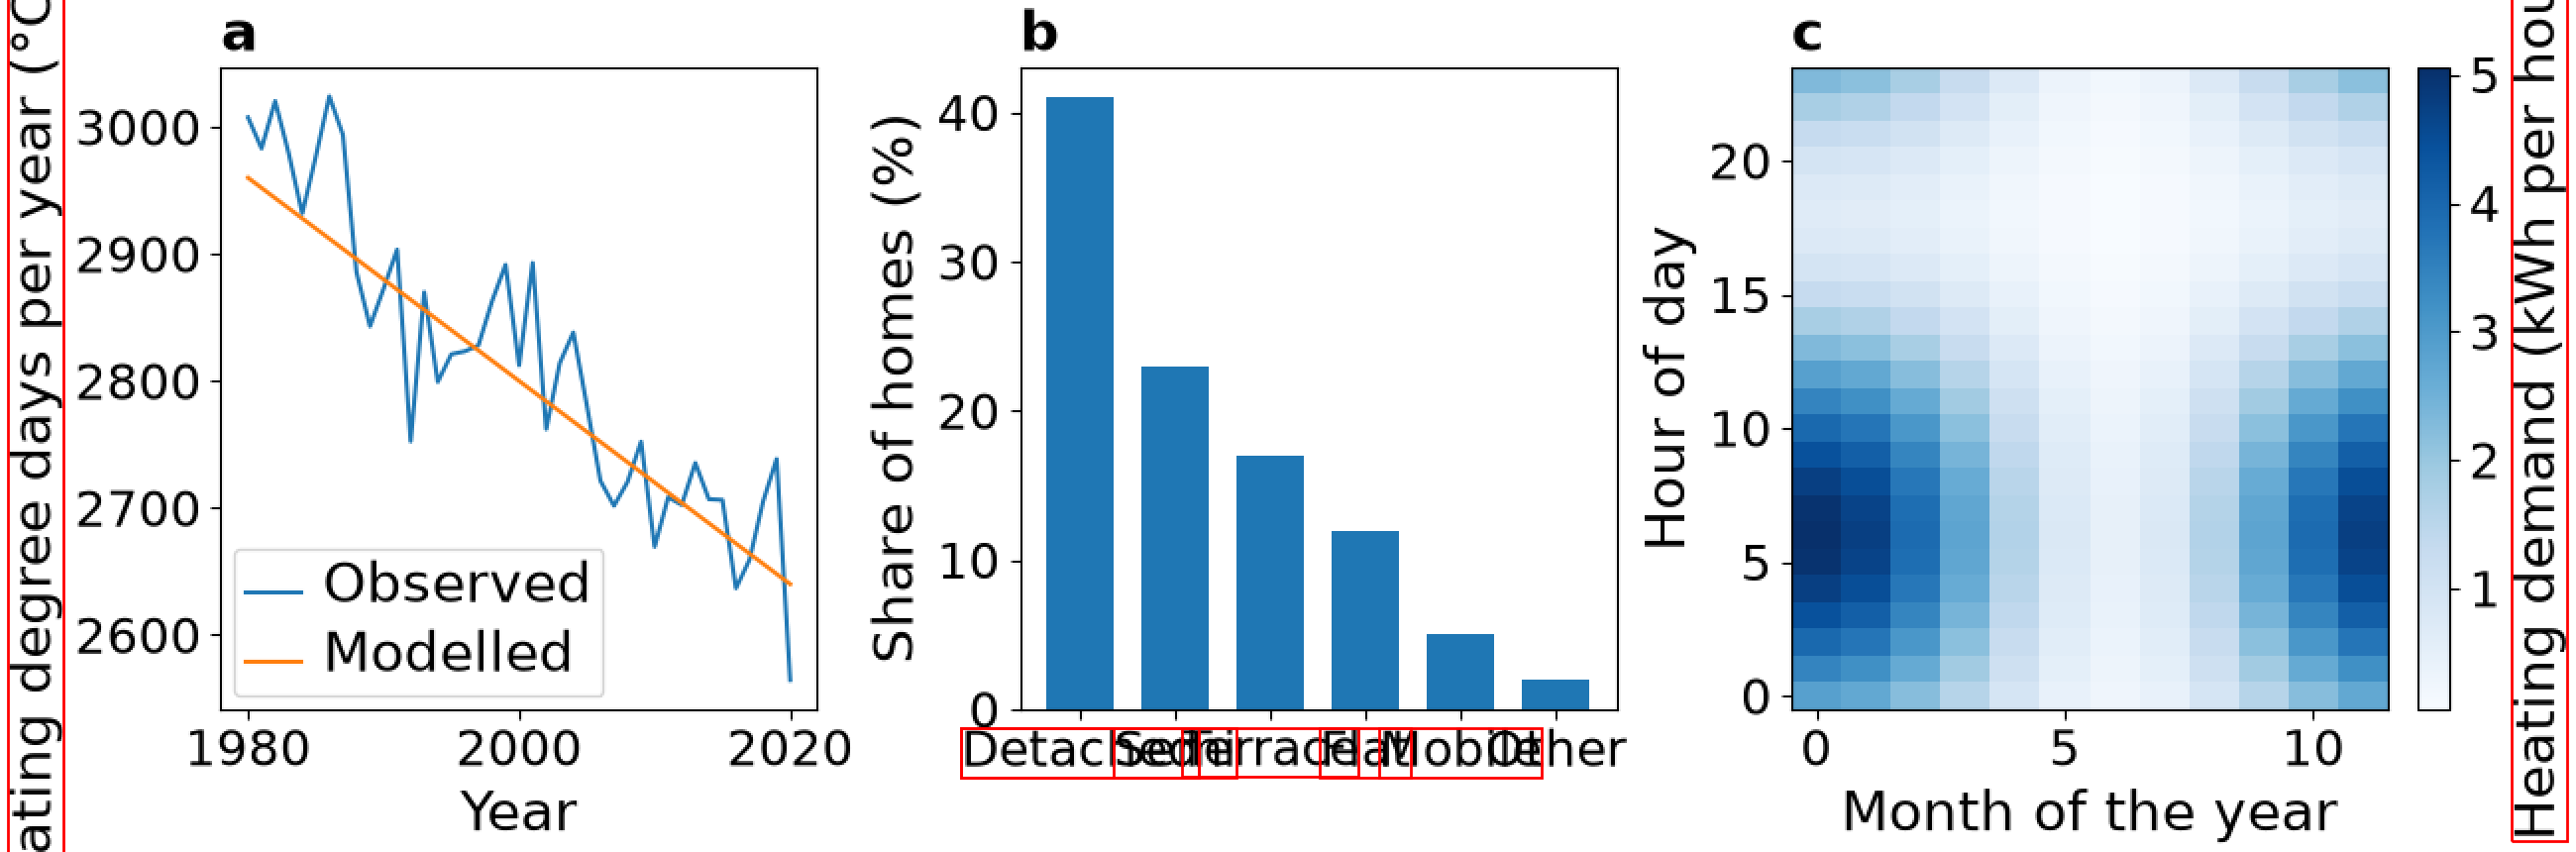

In [16]:
def show_marked(fig, problems):
    """A picture of `fig` with a red box round each piece of colliding text."""
    fig.canvas.draw()
    picture = np.asarray(fig.canvas.buffer_rgba())
    height, width = picture.shape[:2]
    marked = plt.figure(figsize=fig.get_size_inches(), dpi=fig.dpi)
    ax = marked.add_axes([0, 0, 1, 1])
    ax.imshow(picture, extent=(0, width, 0, height))
    ax.set(xlim=(0, width), ylim=(0, height))
    ax.axis("off")
    for text, other, why in problems:
        box = text.get_window_extent()
        ax.add_patch(plt.Rectangle((box.x0, box.y0), box.width, box.height,
                                   fill=False, color="red", clip_on=False))

problems = figfont.overlaps(fig, edges=True)
show_marked(fig, problems)

## 7. Fix colliding text

`fit` clears the collisions with the smallest change that works for each one. It never changes a
font size, a colour, the data, the wording or the width of the figure. It prints what it did and
returns the number of collisions left.

TEXT DENSITY fig01: median 0.3243 ems 10.7 min 10.7 panels 0.3843 0.2417 0.3243 | ems 10.7 10.7 10.7


TEXT FIXED fig01: wrap 2, pads 6, ticks 4


TEXT OK fig01: no overlaps


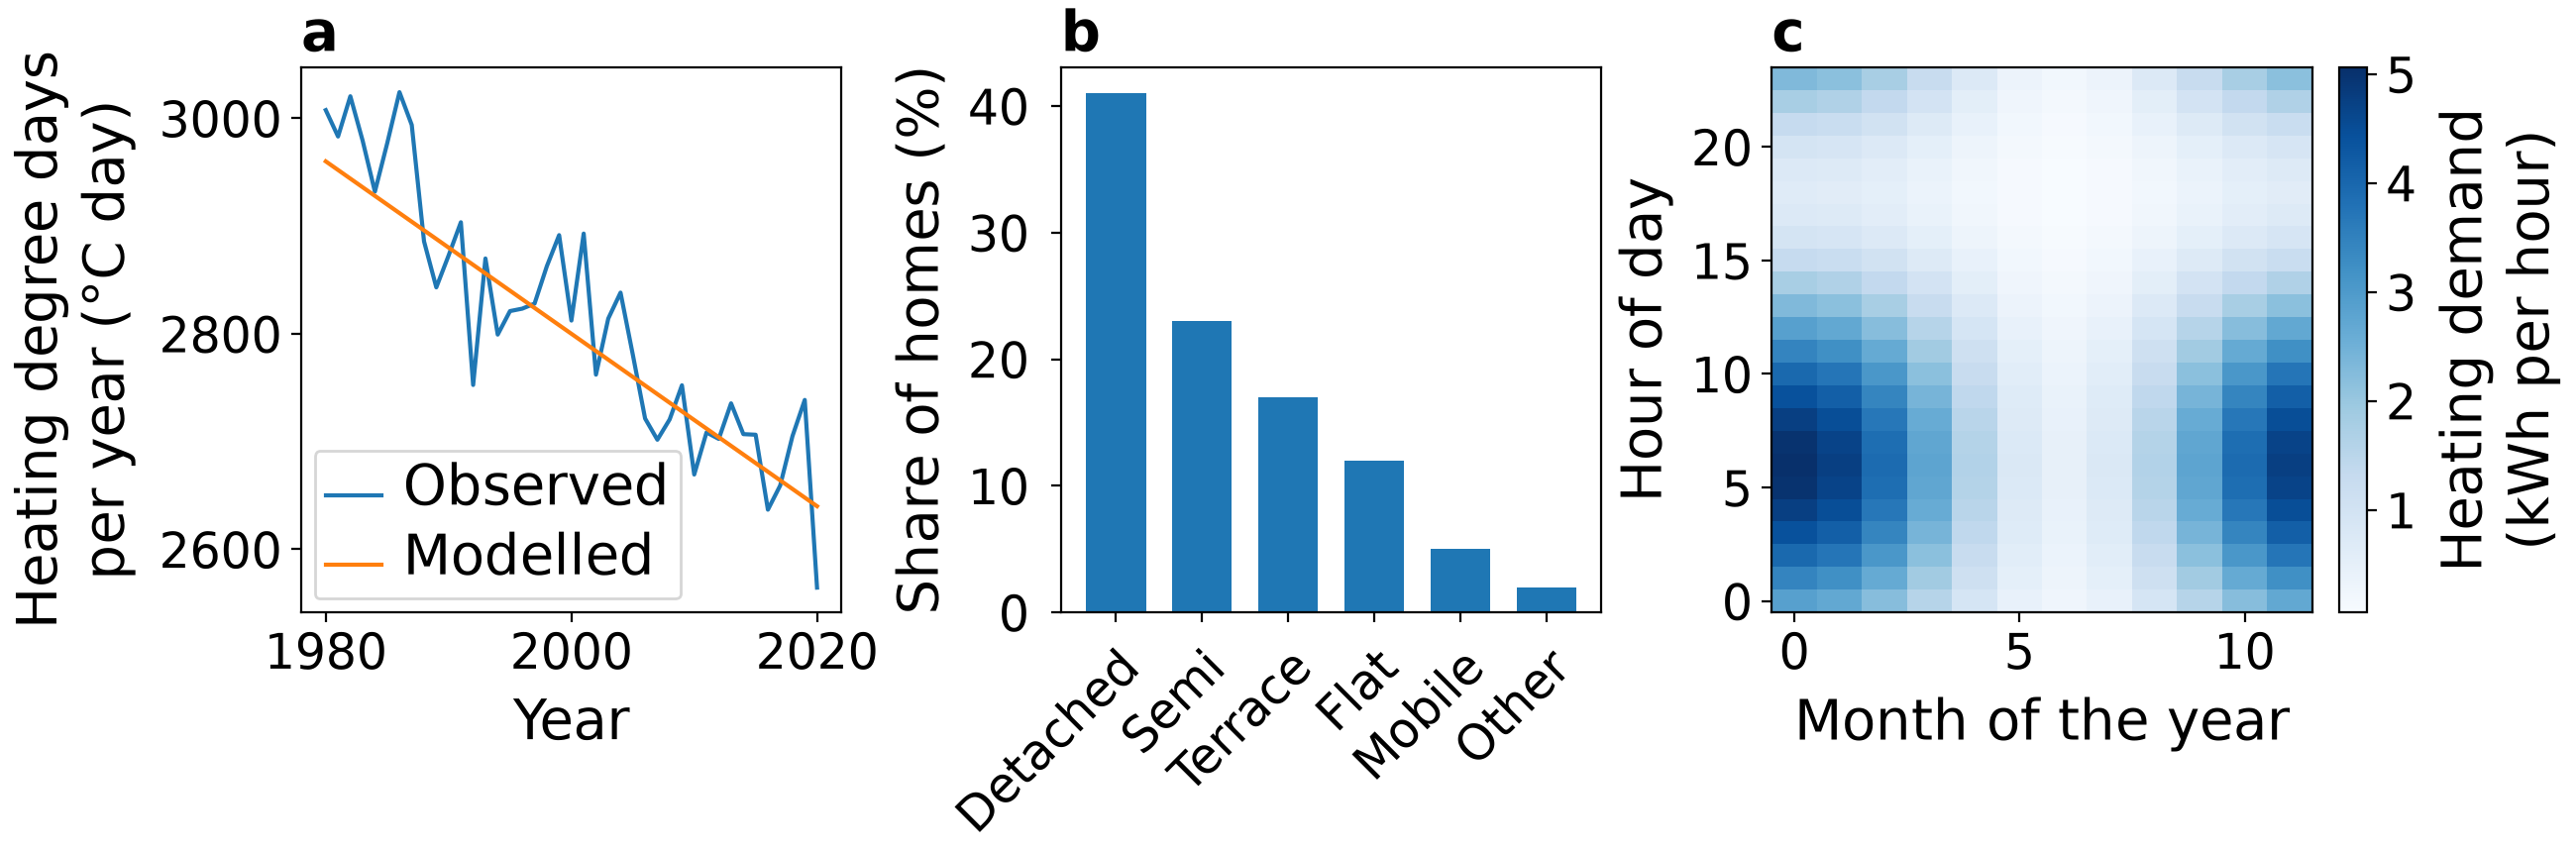

In [17]:
left = figfont.fit(fig, "fig01", edges=True)
fig

`TEXT FIXED` lists the steps that changed something and how many times. Here the long labels went
onto two lines (`wrap`), the axis labels moved off their numbers (`pads`) and the bar names
tilted (`ticks`). `TEXT OK` means nothing touches any more. The first line, `TEXT DENSITY`, is the
panel measurement that section 9 explains.

The README has a before-and-after picture for each of the ten steps.

## 8. Measure it again

Save the figure and measure the file, the way a reader will see it.

In [18]:
fig.savefig(out / "fig01.pdf")
fig.savefig(out / "fig01.png", dpi=300)

final_result = figfont.figure(out / "fig01.pdf", printed_width=PAGE)
figfont.verdict(final_result)

{'name': 'fig01.pdf',
 'method': 'text',
 'n': 43,
 'median_pt': 7.0,
 'p10_pt': 7.0,
 'p90_pt': 8.0,
 'reference_median_pt': 7.97,
 'reference_range_pt': [7.39, 8.97],
 'verdict': 'small',
 'scale_to_reference': 1.14}

The median is 7 pt because most of the text in a figure is tick numbers, and those are set to
7 pt. That sits just under the middle half of all papers, so the verdict is still `small`.
Against Nature, whose figures print smaller, it is `ok`:

In [19]:
figfont.verdict(final_result, journal="Nature")["verdict"]

'ok'

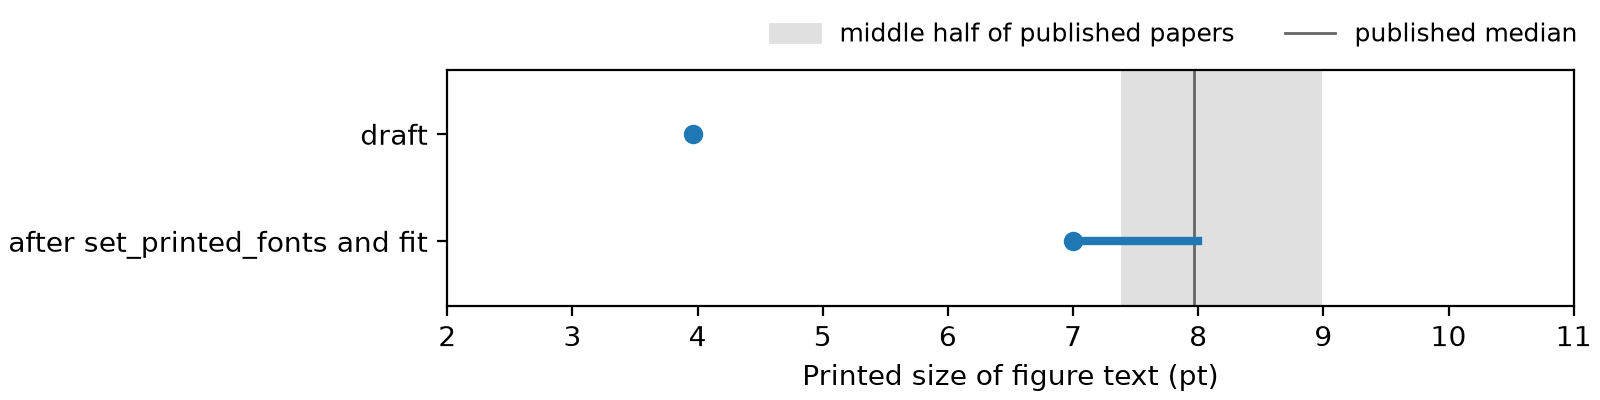

In [20]:
against_papers({"draft": draft_result, "after set_printed_fonts and fit": final_result})

### When there is only an image

A PNG stores no font sizes. `figure` then reads the text off the pixels (OCR) and converts the
height of each line to points. `figure_ocr` is the function behind it. It is close, not exact:

In [21]:
by_ocr = figfont.figure_ocr(out / "fig01.png", printed_width=PAGE)
by_ocr.summary()

{'name': 'fig01.png',
 'method': 'ocr',
 'n': 24,
 'median_pt': 6.81,
 'p10_pt': 6.15,
 'p90_pt': 9.4}

## 9. Pick a size for small panels

8 pt is the published average, but it comes mostly from figures with a few large panels. On a
grid of small panels, 8 pt words are as big as the panels, and here the years under one panel
run into the years under the next. This grid is drawn at its printed width, so 8 pt here is 8 pt
on the page.

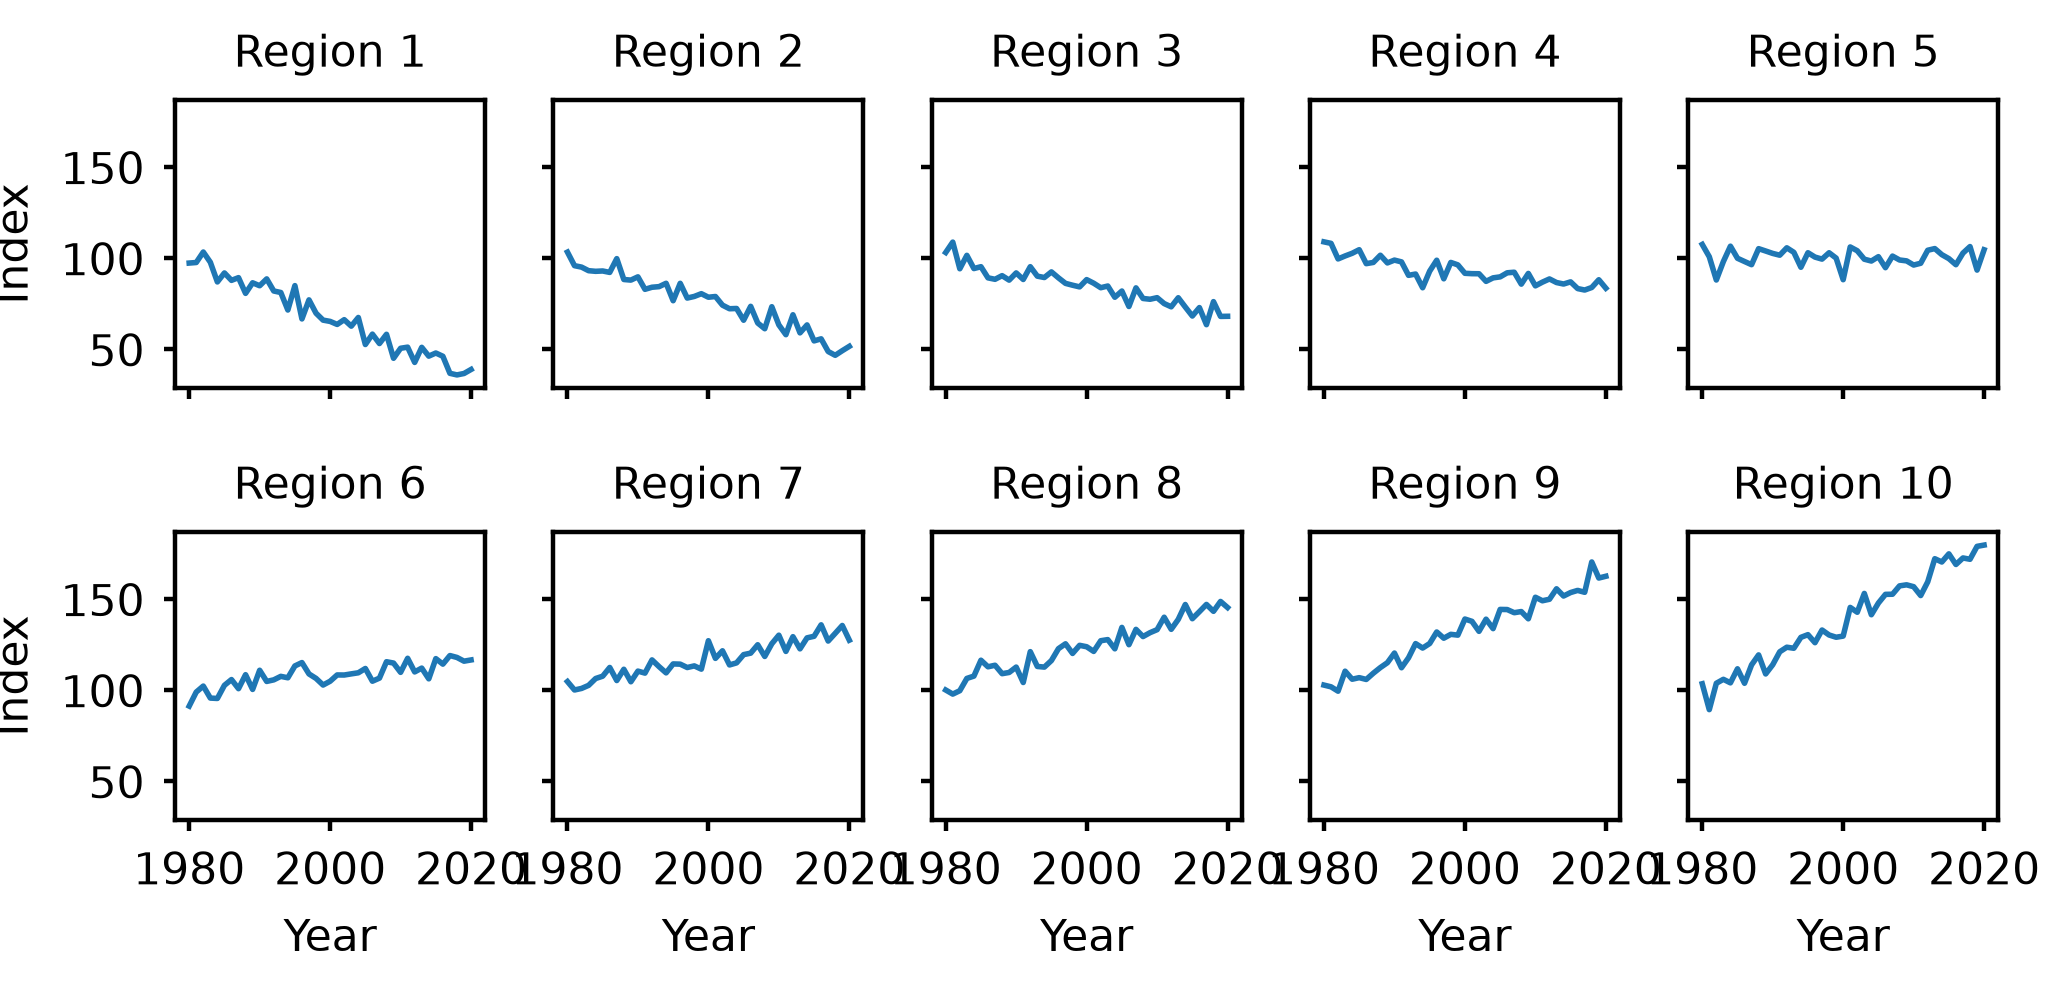

In [22]:
def grid():
    rng = np.random.default_rng(4)
    fig, axes = plt.subplots(2, 5, figsize=(PAGE, 2.5), sharex=True, sharey=True, dpi=200)
    fig.subplots_adjust(left=0.085, right=0.97, top=0.9, bottom=0.18, wspace=0.22, hspace=0.5)
    years = np.arange(1980, 2021)
    for k, ax in enumerate(axes.flat):
        ax.plot(years, 100 + (k - 4) * 0.4 * (years - 1980) + rng.normal(0, 4, years.size), linewidth=1)
        ax.set_title(f"Region {k + 1}", fontsize=8)
        ax.tick_params(labelsize=8, length=2)
        ax.set_xticks([1980, 2000, 2020])
    for ax in axes[1]:
        ax.set_xlabel("Year", fontsize=8)
    for ax in axes[:, 0]:
        ax.set_ylabel("Index", fontsize=8)
    return fig

small = grid()

`density` measures how wide each panel is in heights of its own text. `ems_min` is the narrowest
panel.

In [23]:
measured = figfont.density(small)
round(measured["ems_min"], 1), [round(width, 1) for width in measured["panel_ems"]]

(7.0, [7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0])

Panels read well when they are at least 15 text heights wide. `suggest_size` picks the size that
gets the narrowest panel there, and keeps it between 6 and 8 pt. These panels are too small to
reach 15 at any size in that range, so the answer is the smallest it allows.

In [24]:
size = figfont.suggest_size(small, printed_pt=8)
size

6.0

`scale_fonts` multiplies every font in the figure by one factor, which takes 8 pt to that size:

TEXT DENSITY grid: median 0.1129 ems 9.3 min 9.3 panels 0.1013 0.0000 0.0000 0.0000 0.0000 0.2258 0.1245 0.1245 0.1245 0.1245 | ems 9.3 9.3 9.3 9.3 9.3 9.3 9.3 9.3 9.3 9.3


TEXT FIXED grid: space 2


TEXT OK grid: no overlaps


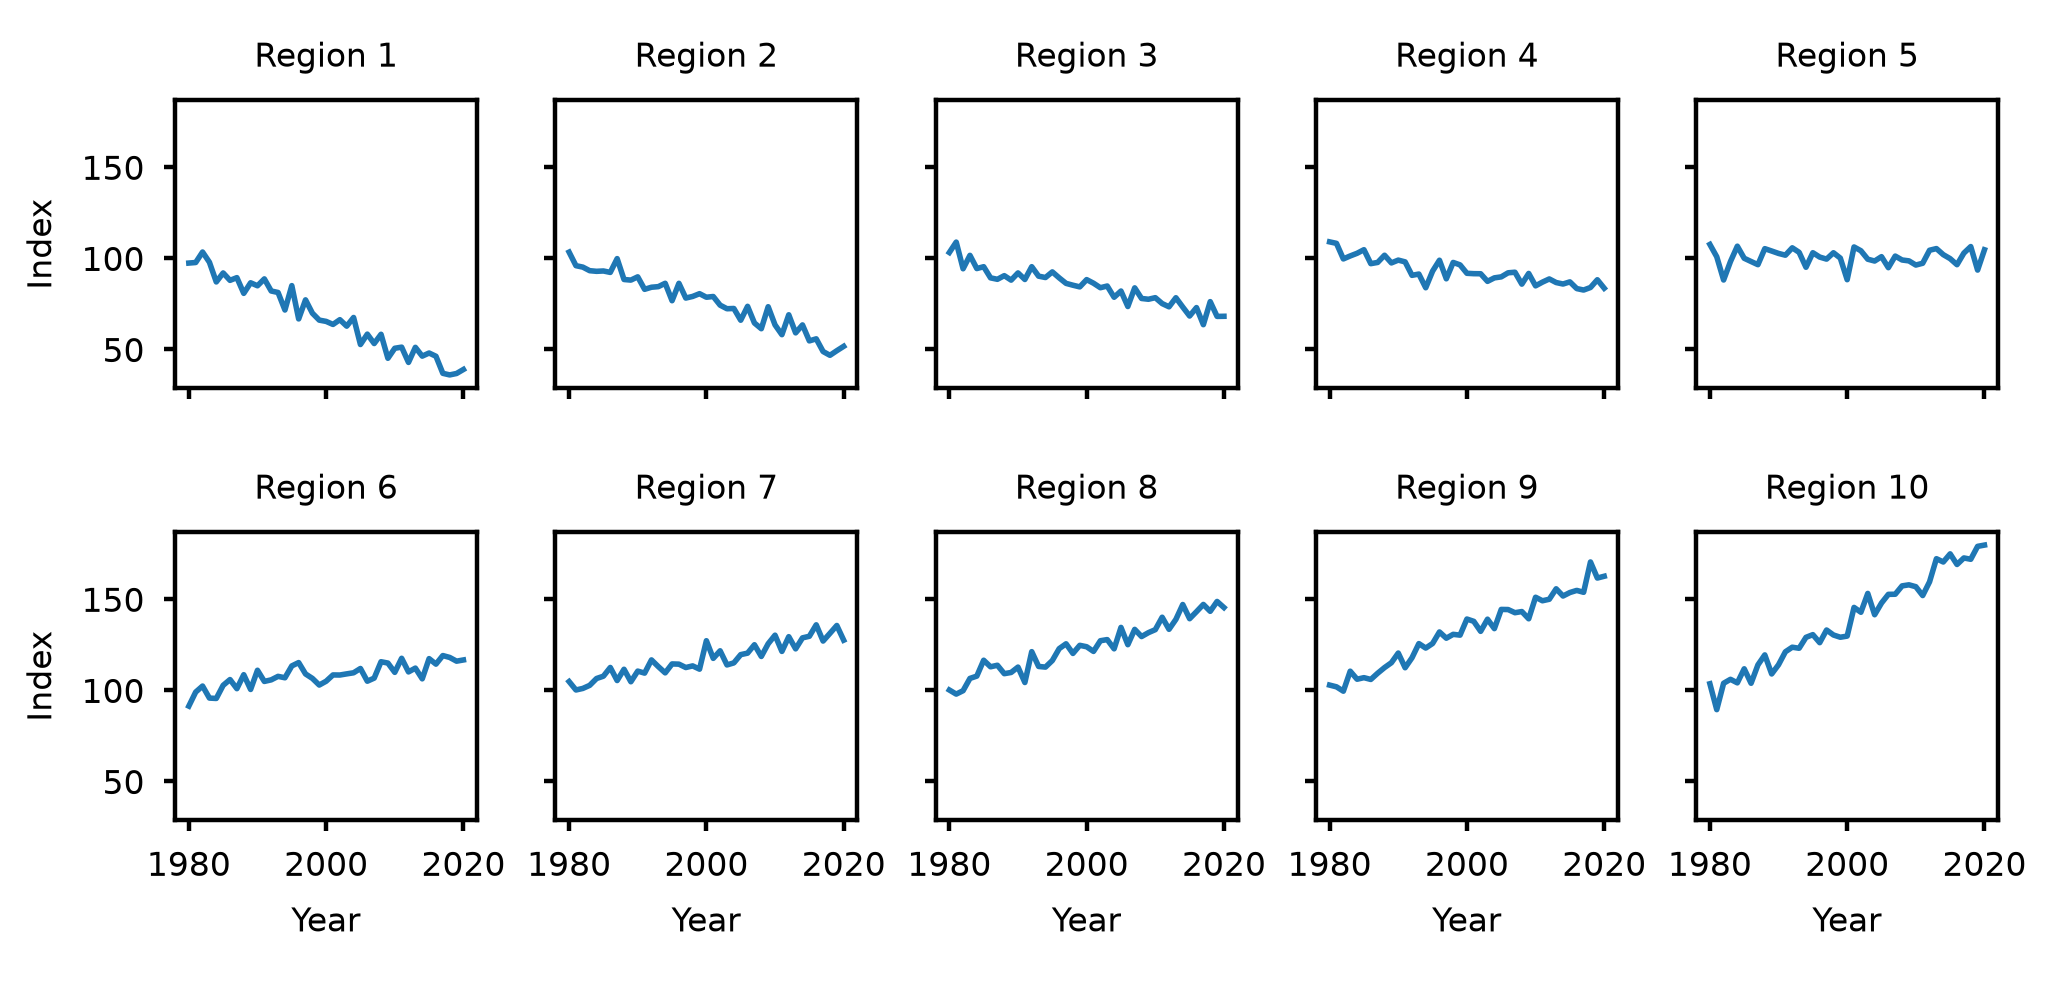

In [25]:
scale_fonts(small, size / 8)
figfont.fit(small, "grid")
small

## 10. Boxed notes on a map

A note with a box round it, such as a season label, is often placed by longitude and latitude,
and lands on a coast when the map or the text changes size. Here the top label runs into Central
America. (This section needs cartopy.)

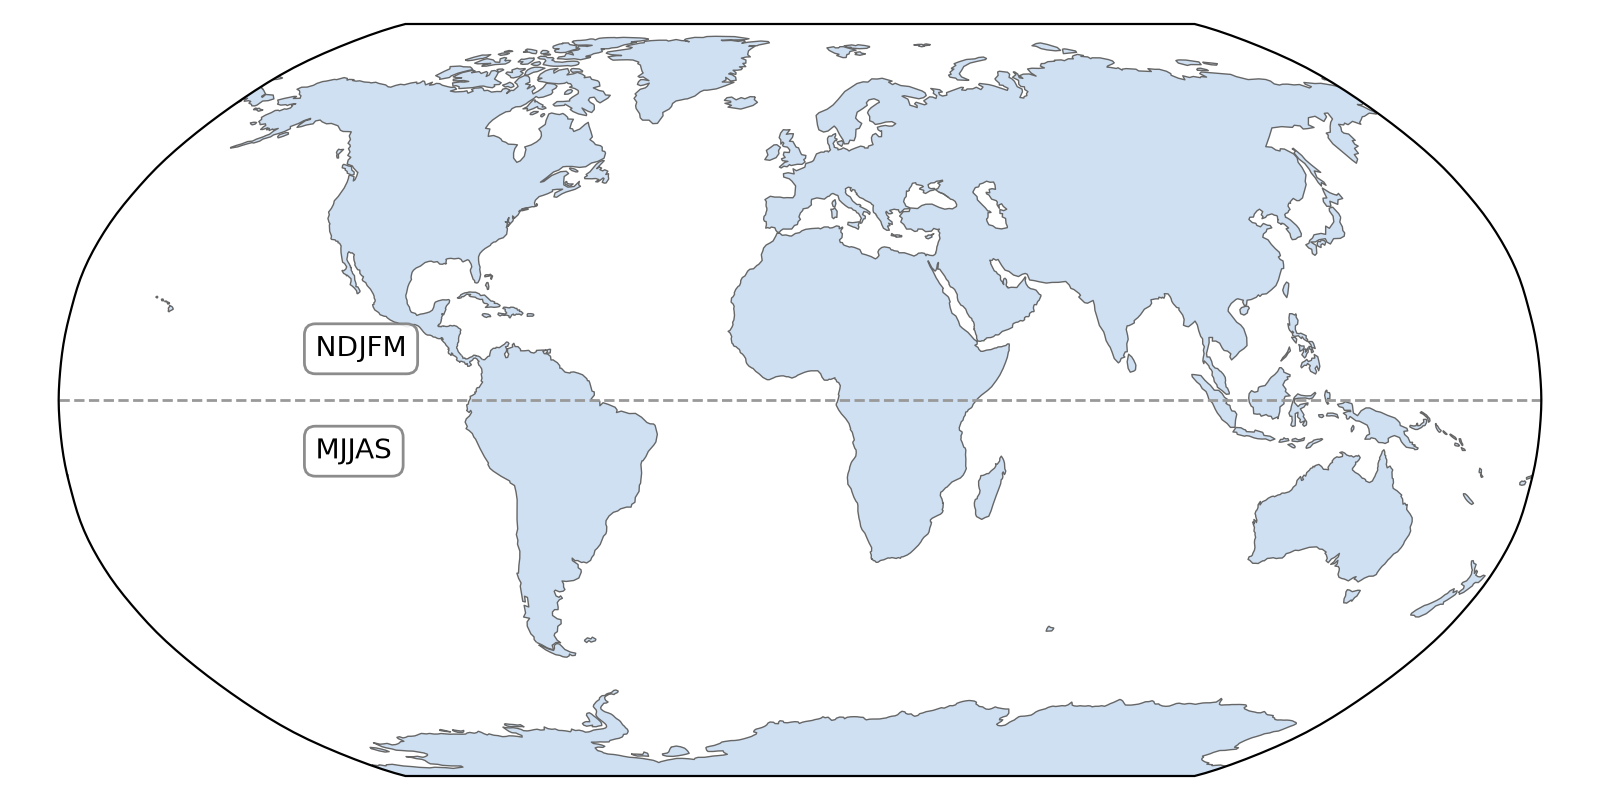

In [26]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# once, before drawing: keeps cartopy's own coordinate labels apart
figfont.textfit.pad_cartopy_labels()

world = plt.figure(figsize=(8, 4))
ax = world.add_axes([0.02, 0.03, 0.96, 0.94], projection=ccrs.Robinson())
ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="#cfe0f3")
ax.coastlines(linewidth=0.5, color="0.4")
# the equator
ax.plot([-180, 180], [0, 0], "--", color="0.6", linewidth=1, transform=ccrs.PlateCarree())
box = dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.5", alpha=0.9)
ax.text(-118, 8, "NDJFM", transform=ccrs.PlateCarree(), ha="left", va="bottom", bbox=box, zorder=10)
ax.text(-118, -8, "MJJAS", transform=ccrs.PlateCarree(), ha="left", va="top", bbox=box, zorder=10);

`clear_notes` moves each such note the shortest way clear of what is drawn. Notes set in line
move together, and a note never crosses a line drawn right across its panel, so each label stays
on its own side of the equator. Here both moved left by the same amount. It returns how many notes it moved and a list of any it could not
find a place for. `fit` runs this as its last step; call `clear_notes` to run it on its own.

2 notes moved, 0 left where they were


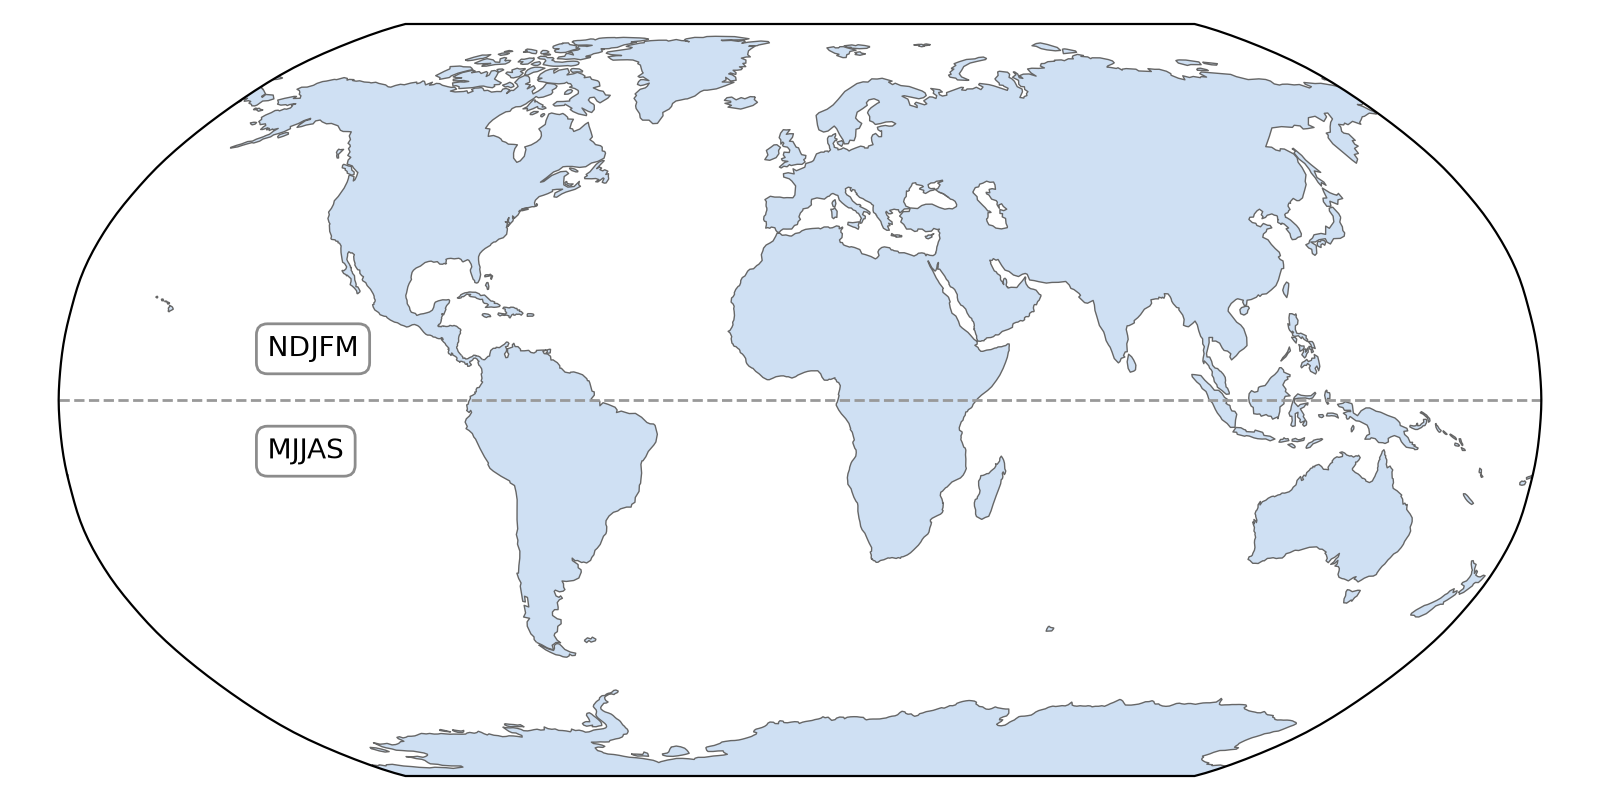

In [27]:
moved, stuck = figfont.clear_notes(world)
print(moved, "notes moved,", len(stuck), "left where they were")
world

## 11. The command line

The measuring half also works on files, without Python. `check` measures figure files at
a printed width and compares them with the published papers:

In [28]:
!figfont check tour_output/draft.pdf tour_output/fig01.pdf --width 5.15

published papers: median 7.97 pt, middle half of papers 7.39-8.97 pt
  draft.pdf                        median  3.96 pt (1.0 mm caps)  p10  3.96  SMALL  x2.01
  fig01.pdf                        median  7.00 pt (1.7 mm caps)  p10  7.00  SMALL  x1.14


A file can carry its own width after `@`, and `--journal` compares with one journal:

In [29]:
!figfont check tour_output/fig01.png@5.15 --journal "Nature"

published papers: median 7.0 pt, middle half of papers 6.0-7.0 pt
  fig01.png                        median  6.81 pt (1.7 mm caps)  p10  6.15  OK     x1.03


`paper` measures the figures inside a compiled paper, and `scale` does the arithmetic of section 2:

In [30]:
!figfont paper examples/paper.pdf

published papers: median 7.97 pt, middle half of papers 7.39-8.97 pt
  paper.pdf                        median  7.00 pt (1.7 mm caps)  p10  7.00  SMALL  x1.14


In [31]:
!figfont scale 8 13 5.15

20.19 pt


## Where next

The [README](../README.md) has a before-and-after picture for each of the ten steps of `fit`, the
table of every function, and what OCR can and cannot measure.